In [1]:
import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt

In [2]:
P = np.array([
    [0, 1/2, 1/2, 0, 0, 0, 0, 0],
    [0, 0, 1/2, 1/2, 0, 0, 0, 0],
    [1/2, 0, 0, 0, 1/2, 0, 0, 0],
    [1/3, 0, 1/3, 0, 1/3, 0, 0, 0],
    [0, 1/3, 0, 0, 0, 1/3, 1/3, 0],
    [0, 0, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 1],
    [0, 0, 0, 0, 0, 0, 1, 0]
])

q_0 = np.ones(8) * 1/8

print(np.round(q_0 @ np.linalg.matrix_power(P, 100), 6))
print(np.round(q_0 @ np.linalg.matrix_power(P, 101), 6))


[0.       0.       0.       0.       0.       0.4375   0.267736 0.294763]
[0.       0.       0.       0.       0.       0.4375   0.294763 0.267736]


# Part b

In [3]:
d = 0.85

G = d*P + ((1 - d) / 8) * np.ones((8,8))
q_0 = np.ones(8) * 1/8

pi_old = q_0 @ np.linalg.matrix_power(G, 1)
for i in range(2, 1000):
    pi_new = q_0 @ np.linalg.matrix_power(G, i)
    if np.linalg.norm(pi_new - pi_old, ord=1) < 10 ** (-10):
        print(np.round(pi_new, 4))
        print(i)
        break
    pi_old = pi_new

print(np.argsort(pi_new, descending = True) + 1)

[0.0718 0.0696 0.0925 0.0483 0.0718 0.2605 0.1983 0.1873]
124
[6 7 8 3 1 5 2 4]


In [4]:
n = G.shape[0]

A = G.T - np.eye(n)

A[-1, :] = 1

b = np.zeros(n)
b[-1] = 1

pi = scipy.linalg.solve(A, b)

np.isclose(pi, pi_new)

array([ True,  True,  True,  True,  True,  True,  True,  True])

# Part c

In [12]:
rng = np.random.default_rng(0)
R, T = 100, 10**5
n = G.shape[0]

cdf = np.cumsum(G, axis=1)     
cdf[:, -1] = 1.0                

# checkpoints (log-spaced) for the error curve
checkpoints = np.unique(np.logspace(2, 5, 40).astype(int))
cp_set = set(checkpoints.tolist())

x = np.zeros(R, dtype=int)        
counts = np.zeros((R, n))     
rows = np.arange(R)

rms_err = []
saved_T = []
for t in range(1, T + 1):
    u = rng.random(R)
    # discrete inverse transform, vectorized over surfers:
    x = (u[:, None] > cdf[x]).sum(axis=1)
    counts[rows, x] += 1

    if t in cp_set:
        pi_hat = counts / t                               # R x 8 time averages
        max_err = np.abs(pi_hat - pi).max(axis=1)         # max_i |pi_hat_i - pi_i| per surfer
        rms_err.append(np.sqrt(np.mean(max_err**2)))      # rms over surfers
        saved_T.append(t)

rms_err = np.array(rms_err)
saved_T = np.array(saved_T)
pi_hat_final = counts / T

print(np.round(pi_hat_final.mean(axis=0), 3))

[0.072 0.07  0.092 0.048 0.072 0.261 0.198 0.187]


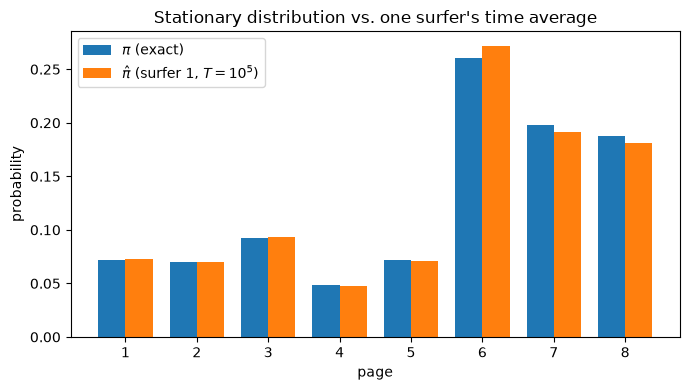

In [20]:
pages = np.arange(1, n + 1)
w = 0.38
plt.figure(figsize=(7, 4))
plt.bar(pages - w/2, pi, w, label=r"$\pi$ (exact)")
plt.bar(pages + w/2, pi_hat_final[0], w, label=r"$\hat\pi$ (surfer 1, $T=10^5$)")
plt.xlabel("page"); plt.ylabel("probability"); plt.legend()
plt.title("Stationary distribution vs. one surfer's time average")
plt.tight_layout()

plt.savefig("/Users/viro3403/Library/CloudStorage/OneDrive-UCB-O365/Desktop/Markov/hw5p3bar.png")

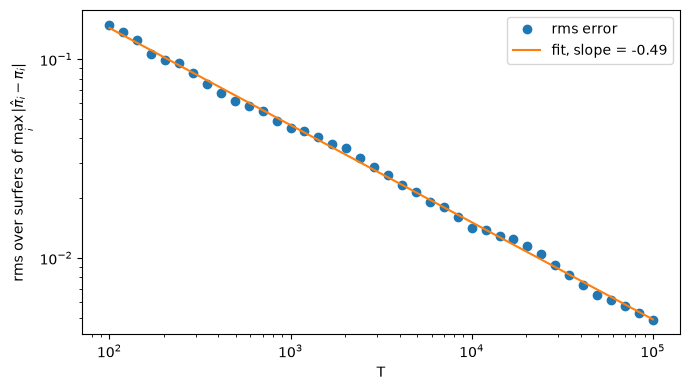

In [21]:

mask = (saved_T >= 1e2) & (saved_T <= 1e5)
slope, intercept = np.polyfit(np.log(saved_T[mask]), np.log(rms_err[mask]), 1)

plt.figure(figsize=(7, 4))
plt.loglog(saved_T, rms_err, "o", label="rms error")
plt.loglog(saved_T, np.exp(intercept) * saved_T**slope, "-",
           label=f"fit, slope = {slope:.2f}")
plt.xlabel("T"); plt.ylabel(r"rms over surfers of $\max_i|\hat\pi_i-\pi_i|$")
plt.legend(); plt.tight_layout();

plt.savefig("/Users/viro3403/Library/CloudStorage/OneDrive-UCB-O365/Desktop/Markov/hw5p3scatter.png")